<a href="https://colab.research.google.com/github/yuki-hogehoge/esol-solubility/blob/main/notebooks/esol_day1_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ESOL水溶解度データの探索的分析(Day 1 最終版)
**問い**:塩素(Cl)を含む分子は、水に溶けにくいのか?

**流れ**
1. データを読み、RDKitで記述子を計算する
2. 溶けやすい/溶けにくい分子を眺めて、仮説を立てる(図1)
3. 全体のデータで、Clの有無による溶解度を比べる
4. 分子量でそろえて比べる(図2)
5. 線形回帰で、ほかの特徴を同時に考慮する(表1)
6. 補足:芳香族原子の割合(AP)を加えた確認、相関表

**メモ**
- `logS` は水への溶解度(mol/L)の常用対数。1違うと溶解度は10倍違う。
- 使った溶解度は、ESOLに記録された**実測値**(`measured log solubility in mols per litre`)。
- `LogP` はRDKitが原子ごとの寄与を足し合わせて計算した**推定値**で、実測値ではない。
- 全セルを実行してから保存すると、出力つきで残る(Colab:ランタイム → すべてのセルを実行)。
- 最後に「記事との対応表」がある。

## 0. 準備

In [1]:
!pip install rdkit -q
!pip install japanize-matplotlib -q || true

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image

# 図の日本語ラベル(日本語フォントが使えない場合は英語ラベルにする)
try:
    import japanize_matplotlib
    JP = True
except Exception:
    JP = False
print("日本語ラベル:", JP)

os.makedirs("figures", exist_ok=True)

日本語ラベル: True


```markdown
### 💡 図を英語表記に強制変更する

図2などで使用されるラベルは `JP` という変数（`True` なら日本語、`False` なら英語）で制御されています。
英語表記にしたい場合は、以下のコードを実行して `JP = False` に設定し、その後にプロットのセルを再実行してください。
```

In [3]:
# 英語表記に強制変更する
JP = False
print("日本語ラベルフラグをオフにしました。JP:", JP)

日本語ラベルフラグをオフにしました。JP: False


## 1. データの読み込み
ESOL(Delaney, 2004)を、MoleculeNet / DeepChem の配布元から読み込む。読み込めない場合は、`delaney-processed.csv` をアップロードして、`pd.read_csv("delaney-processed.csv")` に書き換える。

In [4]:
URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
df_raw = pd.read_csv(URL)
print(df_raw.shape)
df_raw.head()

(1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [5]:
data = df_raw[["Compound ID", "smiles", "measured log solubility in mols per litre"]].copy()
data.columns = ["name", "smiles", "logS"]
data["mol"] = data["smiles"].apply(Chem.MolFromSmiles)
print("化合物数:", len(data), "/ 変換に失敗:", data["mol"].isna().sum())

化合物数: 1128 / 変換に失敗: 0


## 2. 記述子の計算
- `MolWt`:分子量
- `LogP`:水より油になじみやすい度合い(RDKitの推定値)
- `TPSA`:極性表面積
- `RotBonds`:回転可能結合の数
- `nCl`:Cl原子の数
- `AP`:芳香族原子の割合(重原子のうち芳香族の割合)。ESOL原論文のモデルで有意だった特徴。
- `nBenzene`:6原子すべてが炭素の芳香環(ベンゼン環)の数

In [6]:
benz = Chem.MolFromSmarts("c1ccccc1")
cl = Chem.MolFromSmarts("[Cl]")

def aromatic_proportion(m):
    return sum(a.GetIsAromatic() for a in m.GetAtoms()) / m.GetNumHeavyAtoms()

data["MolWt"] = data["mol"].apply(Descriptors.MolWt)
data["LogP"] = data["mol"].apply(Descriptors.MolLogP)
data["TPSA"] = data["mol"].apply(Descriptors.TPSA)
data["HDonors"] = data["mol"].apply(Descriptors.NumHDonors)
data["HAcceptors"] = data["mol"].apply(Descriptors.NumHAcceptors)
data["RotBonds"] = data["mol"].apply(Descriptors.NumRotatableBonds)
data["nCl"] = data["mol"].apply(lambda m: len(m.GetSubstructMatches(cl)))
data["hasCl"] = data["nCl"] > 0
data["AP"] = data["mol"].apply(aromatic_proportion)
data["nBenzene"] = data["mol"].apply(lambda m: len(m.GetSubstructMatches(benz)))

data[["name", "logS", "MolWt", "LogP", "TPSA", "RotBonds", "nCl", "AP", "nBenzene"]].head()

,name,logS,MolWt,LogP,TPSA,RotBonds,nCl,AP,nBenzene
0,Amigdalin,-0.77,457.432,-3.10802,202.32,7,0,0.187500,1
1,Fenfuram,-3.30,201.225,2.84032,42.24,2,0,0.733333,1
2,citral,-2.06,152.237,2.87800,17.07,4,0,0.000000,0
3,Picene,-7.87,278.354,6.29940,0.00,0,0,1.000000,5
4,Thiophene,-1.33,84.143,1.74810,0.00,0,0,1.000000,0


## 3. 身近な物質の溶解度(記事の導入)
パラジクロロベンゼン(防虫剤)と砂糖(スクロース)のlogSを、データから探す。
SMILESは同じ分子でも書き方が複数あるため、**立体情報を外した正規化SMILES**で比べる。

`溶解度[g/L] ≈ 10^logS × 分子量`。ただし、mol/Lの「L」は本来**溶液**の体積。砂糖のように大量に溶ける物質では、「水1リットルに」とは言い切れない点に注意。

In [7]:
def flat(smi):
    m = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(m, isomericSmiles=False)

data["flat"] = data["smiles"].apply(flat)

targets = {
    "パラジクロロベンゼン": flat("Clc1ccc(Cl)cc1"),
    "スクロース(砂糖)": flat("OC[C@H]1O[C@H](O[C@]2(CO)O[C@H](CO)[C@@H](O)[C@@H]2O)[C@H](O)[C@@H](O)[C@@H]1O"),
}
found = {}
for label, f in targets.items():
    hit = data[data["flat"] == f]
    print(label, "→ 見つかった件数:", len(hit))
    if len(hit):
        r = hit.iloc[0]
        found[label] = r
        print(f"  logS = {r['logS']:.2f},  分子量 = {r['MolWt']:.1f},  10^logS × 分子量 ≈ {10 ** r['logS'] * r['MolWt']:.3g} g/L")

if len(found) == 2:
    d = found["スクロース(砂糖)"]["logS"] - found["パラジクロロベンゼン"]["logS"]
    print(f"\nlogSの差 = {d:.2f}  →  溶解度の比 ≈ {10 ** d:,.0f} 倍")

パラジクロロベンゼン → 見つかった件数: 1
  logS = -3.27,  分子量 = 147.0,  10^logS × 分子量 ≈ 0.0789 g/L
スクロース(砂糖) → 見つかった件数: 1
  logS = 0.79,  分子量 = 342.3,  10^logS × 分子量 ≈ 2.11e+03 g/L

logSの差 = 4.06  →  溶解度の比 ≈ 11,482 倍


## 4. 図1:溶けやすい4化合物と、溶けにくい4化合物
Cl原子を赤で強調する。

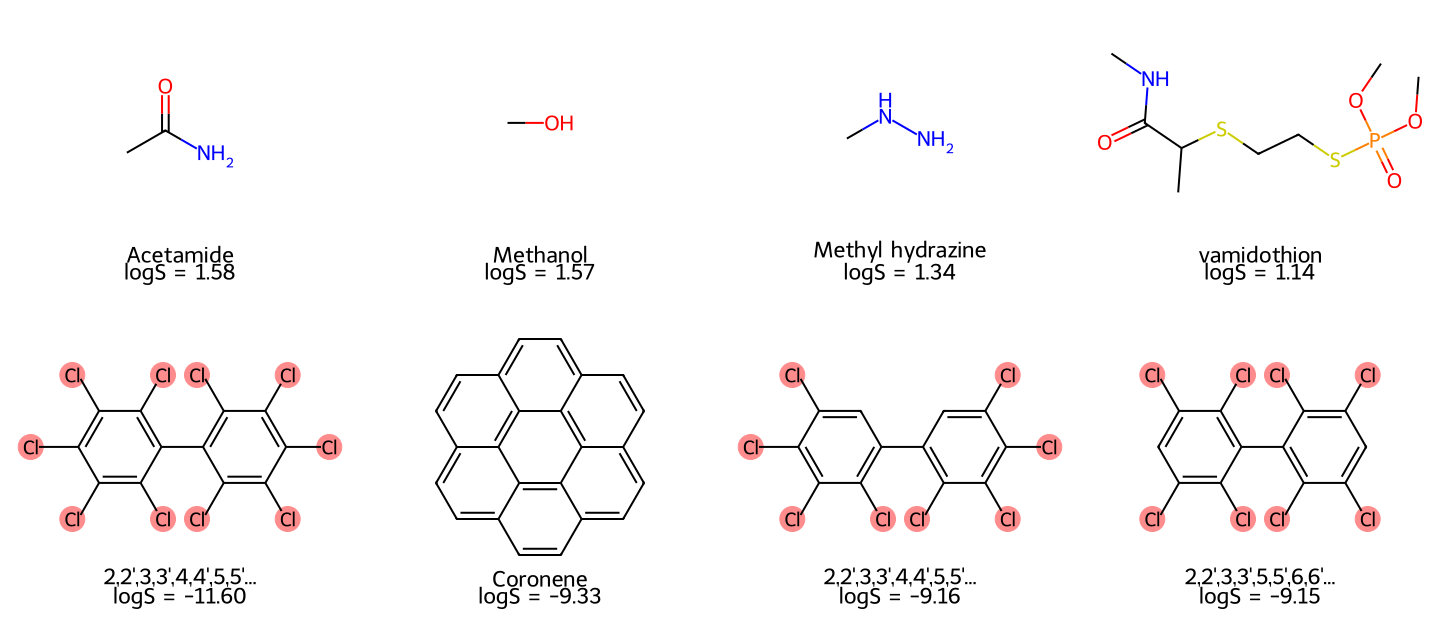

下位4化合物のうち、Clを含む数: 3
上位4化合物のうち、Clを含む数: 0


In [8]:
def short(name, n=22):
    return name if len(name) <= n else name[: n - 3] + "..."

def draw_group(sub, per_row=4, subimg=(360, 300), legend_size=22):
    mols = list(sub["mol"])
    legends = [f"{short(n)}\nlogS = {s:.2f}" for n, s in zip(sub["name"], sub["logS"])]
    hl_atoms = [[a.GetIdx() for a in m.GetAtoms() if a.GetSymbol() == "Cl"] for m in mols]
    opts = rdMolDraw2D.MolDrawOptions()
    opts.legendFontSize = legend_size
    opts.legendFraction = 0.2
    opts.setHighlightColour((1.0, 0.55, 0.55))
    opts.highlightRadius = 0.45
    opts.baseFontSize = 0.7
    return Draw.MolsToGridImage(mols, molsPerRow=per_row, subImgSize=subimg, legends=legends,
                                highlightAtomLists=hl_atoms, drawOptions=opts)

top4 = data.nlargest(4, "logS")
bottom4 = data.nsmallest(4, "logS")

top_img, bottom_img = draw_group(top4), draw_group(bottom4)
gap = 24
W = max(top_img.width, bottom_img.width)
fig1 = Image.new("RGB", (W, top_img.height + gap + bottom_img.height), "white")
fig1.paste(top_img, (0, 0))
fig1.paste(bottom_img, (0, top_img.height + gap))
fig1.save("figures/fig1_structures.png", dpi=(300, 300))
display(fig1)

print("下位4化合物のうち、Clを含む数:", int(bottom4["hasCl"].sum()))
print("上位4化合物のうち、Clを含む数:", int(top4["hasCl"].sum()))

**考察**
- 溶けやすい4化合物は、OH基・NH2基・アミドのNHなど、水と水素結合を作れる部位を持つ。
- 溶けにくい4化合物は、いずれもベンゼン環を含み、そのうち3つにClが含まれる(残る1つのコロネンは、Clを含まないが、ベンゼン環が多数つながった大きな分子)。
- ここまでは「眺めた印象」。以降で、全体のデータで確かめる。

## 5. 全体のデータで、Clの有無を比べる

In [9]:
by_cl = data.groupby("hasCl")["logS"].agg(["count", "mean"]).round(2)
display(by_cl)

diff_all = by_cl.loc[True, "mean"] - by_cl.loc[False, "mean"]
print(f"logSの平均の差(Clあり − Clなし) = {diff_all:.2f}  →  溶解度の比 ≈ {10 ** abs(diff_all):.0f} 倍(Clありのほうが低い)")
print("nCl と logS の相関:", round(data["nCl"].corr(data["logS"]), 2))

,count,mean
hasCl,,
False,876,-2.73
True,252,-4.17


logSの平均の差(Clあり − Clなし) = -1.44  →  溶解度の比 ≈ 28 倍(Clありのほうが低い)
nCl と logS の相関: -0.39


Clを含む分子は、そもそも大きい分子に偏っていないか(平均分子量を比べる)。

In [10]:
mw = data.groupby("hasCl")["MolWt"].mean().round(0)
display(mw)
print(f"Clあり/なしの平均分子量の比 = {mw[True] / mw[False]:.2f}")

,MolWt
hasCl,
False,189.0
True,258.0


Clあり/なしの平均分子量の比 = 1.37


## 6. 下位10・上位10化合物の確認
図1は4化合物ずつだったので、10化合物ずつに広げて確認する(記事の2章に対応)。

In [11]:
bottom10 = data.nsmallest(10, "logS")
top10 = data.nlargest(10, "logS")

print("溶けにくい10化合物:ベンゼン環の数")
display(bottom10[["name", "logS", "nBenzene", "nCl", "MolWt"]].round(2))
print("すべて2個以上のベンゼン環を持つ:", bool((bottom10["nBenzene"] >= 2).all()))
print("そのうちClを含む化合物の数:", int(bottom10["hasCl"].sum()))
print("平均分子量(溶けにくい10 / 溶けやすい10):", round(bottom10["MolWt"].mean()), "/", round(top10["MolWt"].mean()))

# 溶けやすい10化合物が、OH基またはNH2基を持つか
oh = Chem.MolFromSmarts("[OX2H]")
nh2 = Chem.MolFromSmarts("[NX3;H2]")
top10 = top10.assign(
    OH=top10["mol"].apply(lambda m: m.HasSubstructMatch(oh)),
    NH2=top10["mol"].apply(lambda m: m.HasSubstructMatch(nh2)),
)
display(top10[["name", "logS", "OH", "NH2"]].round(2))
print("OH基またはNH2基を持つ化合物の数:", int((top10["OH"] | top10["NH2"]).sum()))

溶けにくい10化合物:ベンゼン環の数


,name,logS,nBenzene,nCl,MolWt
603,"2,2',3,3',4,4',5,5',6,6'-PCB",-11.60,2,10,498.66
718,Coronene,-9.33,7,0,300.36
297,"2,2',3,3',4,4',5,5'-PCB",-9.16,2,8,429.77
60,"2,2',3,3',5,5',6,6'-PCB",-9.15,2,8,429.77
676,Benzo[ghi]perylene,-9.02,6,0,276.34
879,"2,2',3,4,5,5',6-PCB",-8.94,2,7,395.33
220,Perylene,-8.80,5,0,252.32
871,"2,2',4,4',6,6'-PCB",-8.71,2,6,360.88
637,Benzo(a)pyrene,-8.70,5,0,252.32
54,"2,2',3,3',5,6-PCB",-8.60,2,6,360.88


すべて2個以上のベンゼン環を持つ: True
そのうちClを含む化合物の数: 6
平均分子量(溶けにくい10 / 溶けやすい10): 356 / 99


,name,logS,OH,NH2
605,Acetamide,1.58,False,True
146,Methanol,1.57,True,False
201,Methyl hydrazine,1.34,False,True
1064,vamidothion,1.14,False,False
679,Glycerol,1.12,True,False
687,"N,N-Dimethylacetamide",1.11,False,False
186,Pyridazine,1.10,False,False
365,Pyrimidine,1.10,False,False
983,Ethanol,1.10,True,False
276,Sorbitol,1.09,True,False


OH基またはNH2基を持つ化合物の数: 6


## 7. 分子量でそろえて比べる(図2)
データ数がほぼ均等になるよう、分子量を4つのグループ(四分位)に分け、グループごとにClの有無で平均logSを比べる。

In [12]:
data["MolWt_bin"] = pd.qcut(data["MolWt"], 4)

g = (data.groupby(["MolWt_bin", "hasCl"], observed=True)["logS"]
         .agg(["mean", "count"]).unstack("hasCl"))
mean_no, mean_yes = g["mean"][False], g["mean"][True]
n_no, n_yes = g["count"][False], g["count"][True]
diff = mean_yes - mean_no

summary = pd.DataFrame({
    "Clなし_n": n_no, "Clなし_平均logS": mean_no.round(2),
    "Clあり_n": n_yes, "Clあり_平均logS": mean_yes.round(2),
    "差(あり−なし)": diff.round(2),
    "Cl含有の割合": (n_yes / (n_no + n_yes)).round(2),
})
display(summary)
print(f"最も重いグループの差 {diff.iloc[-1]:.2f} → 溶解度の比 ≈ {10 ** abs(diff.iloc[-1]):.1f} 倍")

,Clなし_n,Clなし_平均logS,Clあり_n,Clあり_平均logS,差(あり−なし),Cl含有の割合
MolWt_bin,,,,,,
"(16.041999999999998, 121.183]",261,-1.30,22,-1.51,-0.21,0.08
"(121.183, 182.179]",237,-2.41,44,-2.35,0.06,0.16
"(182.179, 270.372]",211,-3.55,72,-3.77,-0.21,0.25
"(270.372, 780.949]",167,-4.38,114,-5.63,-1.25,0.41


最も重いグループの差 -1.25 → 溶解度の比 ≈ 17.9 倍


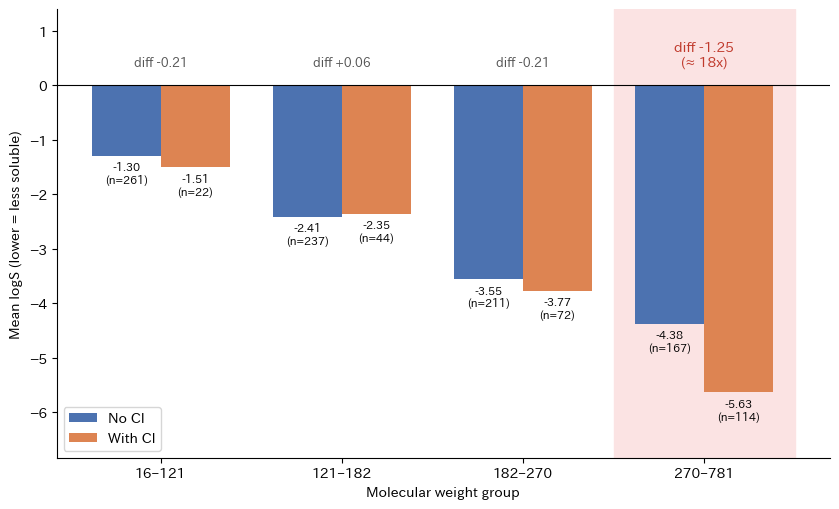

In [13]:
L = {
    "x": "分子量グループ" if JP else "Molecular weight group",
    "y": "logSの平均(下に伸びるほど溶けにくい)" if JP else "Mean logS (lower = less soluble)",
    "no": "Clなし" if JP else "No Cl",
    "yes": "Clあり" if JP else "With Cl",
    "diff": "差" if JP else "diff",
    "x_unit": "倍" if JP else "x",
}
labels = [f"{int(round(iv.left))}–{int(round(iv.right))}" for iv in g.index]
x = np.arange(len(g))
w = 0.38

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.axvspan(x[-1] - 0.5, x[-1] + 0.5, color="#FBE3E3", zorder=0)
ax.bar(x - w / 2, mean_no, w, label=L["no"], color="#4C72B0", zorder=2)
ax.bar(x + w / 2, mean_yes, w, label=L["yes"], color="#DD8452", zorder=2)

for xi, m, n in zip(x - w / 2, mean_no, n_no):
    ax.text(xi, m - 0.1, f"{m:.2f}\n(n={n})", ha="center", va="top", fontsize=8)
for xi, m, n in zip(x + w / 2, mean_yes, n_yes):
    ax.text(xi, m - 0.1, f"{m:.2f}\n(n={n})", ha="center", va="top", fontsize=8)

for i, d in enumerate(diff):
    if i == len(diff) - 1:
        ax.text(x[i], 0.3, f"{L['diff']} {d:+.2f}\n(≈ {10 ** abs(d):.0f}{L['x_unit']})",
                ha="center", va="bottom", fontsize=10, fontweight="bold", color="#C0392B")
    else:
        ax.text(x[i], 0.3, f"{L['diff']} {d:+.2f}", ha="center", va="bottom", fontsize=9, color="#555555")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel(L["x"])
ax.set_ylabel(L["y"])
ax.set_ylim(min(mean_no.min(), mean_yes.min()) - 1.2, 1.4)
ax.legend(loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig2_logS_by_MolWt_Cl.png", dpi=200, bbox_inches="tight")
plt.show()

分子量が最大のグループ以外のClの有無の溶解度差は無視できるのか？

logSは対数だから、0.2は、倍率にすると約1.6倍で、決して小さくないようにみえる。

ただし、判断の基準は、グループ内のばらつきとの比較である。

logSは全体で、+1から-11まで広く散らばっている。ばらつきが大きいと、グループ内の平均の差が0.2程度なら、誤差の範囲かもしれない。

特に、最も軽いグループのClありは、22個しかない。

In [14]:
#グループ内のばらつきとの比較
from scipy import stats

rows = []
for iv, grp in data.groupby("MolWt_bin", observed=True):
    a = grp.loc[~grp["hasCl"], "logS"]
    b = grp.loc[grp["hasCl"], "logS"]
    t, p = stats.ttest_ind(b, a, equal_var=False)
    rows.append({
        "分子量グループ": f"{iv.left:.0f}–{iv.right:.0f}",
        "差": round(b.mean() - a.mean(), 2),
        "標準偏差(Clなし)": round(a.std(), 2),
        "標準偏差(Clあり)": round(b.std(), 2),
        "P値": "<0.001" if p < 0.001 else round(p, 3),
    })
display(pd.DataFrame(rows))

,分子量グループ,差,標準偏差(Clなし),標準偏差(Clあり),P値
0,16–121,-0.21,1.50,0.81,0.293
1,121–182,0.06,1.37,0.98,0.745
2,182–270,-0.21,1.91,1.28,0.288
3,270–781,-1.25,1.65,1.92,<0.001


分子量下位の3グループでは、Clの有無による平均logSの差は-0.21〜+0.06で、グループ内の標準偏差(0.8〜1.9)に比べて小さく、Welchのt検定でもP値は0.29〜0.75だった。

今回のデータでは、誤差の範囲と区別できなかった。

一方、最も重いグループの差(-1.25)は、P < 0.001でした。

In [15]:
#Clを含む分子だけで平均を取る
g = data.groupby("MolWt_bin", observed=True)
summary = pd.DataFrame({
    "n": g.size(),
    "Cl含有の割合": g["hasCl"].mean(),
    "平均Cl数(全体)": g["nCl"].mean(),
    "平均Cl数(Cl含有のみ)": data[data["hasCl"]].groupby("MolWt_bin", observed=True)["nCl"].mean(),
}).round(2)
summary

,n,Cl含有の割合,平均Cl数(全体),平均Cl数(Cl含有のみ)
MolWt_bin,,,,
"(16.041999999999998, 121.183]",283,0.08,0.11,1.41
"(121.183, 182.179]",281,0.16,0.29,1.86
"(182.179, 270.372]",283,0.25,0.57,2.22
"(270.372, 780.949]",281,0.41,1.32,3.26


**データからいえること**
- 下の3つのグループでは、Clの有無による差はほとんどない(約-0.2、+0.06、-0.2)。
- 最も重いグループだけ、約1.25の差(約18倍)が残る。
- Clを含む分子の割合は、軽いグループで約8%、重いグループで約41%。Clを含む分子は、大きい分子に偏っている。
- 分子量が大きいグループほど、平均Cl数が大きくなる

## 8. 線形回帰で、ほかの特徴を同時に考慮する
`logS` を、`MolWt`・`LogP`・`TPSA`・`RotBonds`・`nCl` で説明する(statsmodelsのOLS)。

In [16]:
X = sm.add_constant(data[["MolWt", "LogP", "TPSA", "RotBonds", "nCl"]])
model = sm.OLS(data["logS"], X).fit()
print(model.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2996      0.073      4.078      0.000       0.155       0.444
MolWt         -0.0043      0.001     -5.911      0.000      -0.006      -0.003
LogP          -0.9404      0.039    -24.352      0.000      -1.016      -0.865
TPSA          -0.0094      0.002     -4.505      0.000      -0.013      -0.005
RotBonds       0.0529      0.013      3.924      0.000       0.026       0.079
nCl            0.0590      0.026      2.266      0.024       0.008       0.110


**表の見方**
- `coef`:ほかの特徴を固定したとき、その特徴が1増えるとlogSがどれだけ変わるか。全データに対するベストな推定値。
- `std err`:標準誤差。別のデータセットを与えたときの係数の推定のブレ幅。
- `t`:coef ÷ std err。ブレ幅に比べて効果がしっかり大きければ、t値の絶対値は大きくなる。
- `P>|t|`:「本当は純粋な影響力がゼロなのに、ランダムなノイズの偶然だけで、手元で出た t値 以上に『0から離れすぎた結果』どれくらいの確率で起きるか？」の目安。直接的に影響の大きさを表すものではない。
- `[0.025, 0.975]`:95%信頼区間。0を含まなければ、影響がゼロである可能性は低い。

疑問：
現実には「1つのデータセット」しか手元にないのに、なぜブレ幅がわかるの？
残差（＝予測と実際のズレ）から、「この世界にはどれくらいのノイズ（運や体調などのランダムな揺れ）が混ざっているか」を逆算しているから

「影響ゼロの世界」ってどういうこと？
その着目している変数（Cl数）の『純粋な本当の影響力』がゼロだとしたら、という世界

t, dfからp値を出せるらしい。ここでのt, dfって影響がゼロの世界だと限定していないときの値だよね？そのpの説明にある「影響がゼロの世界」って係数がゼロになっているわけではなくて、係数として0以外の数字が入っているけど、それは他の要因が聞いていて、実際にその特徴は影響していないということ？影響ゼロの世界用にtを計算しなおしているわけではないという理解であっている？あと、t値のガウス分布の両端の面積を計算するとp値と理解しているんだけど、どこで切り取っているの？

### 表1:係数を、溶解度の倍率に直す
logSは常用対数なので、係数を10の肩に乗せると、溶解度の倍率になる。

In [17]:
params, ci, pvals = model.params, model.conf_int(), model.pvalues

items = [("LogPが1上がる", "LogP", 1), ("分子量が100増える", "MolWt", 100), ("Clが1個増える", "nCl", 1)]

def to_text(ratio):
    if ratio < 1:
        return f"約{1 / ratio:.1f}倍 溶けにくい"
    return f"約{ratio:.1f}倍 溶けやすい方向"

rows = []
for label, var, step in items:
    coef = params[var] * step
    lo, hi = sorted([ci.loc[var, 0] * step, ci.loc[var, 1] * step])
    ratio = 10 ** coef
    rows.append({
        "ほかの特徴を一定にした場合": label,
        "logSの変化": f"{coef:+.2f}",
        "溶解度の変化": to_text(ratio),
        "95%信頼区間(溶解度の倍率)": f"{10 ** lo:.2f}〜{10 ** hi:.2f}倍",
        "P値": f"{pvals[var]:.3f}",
    })
table_full = pd.DataFrame(rows)
display(table_full)
table_full.to_csv("figures/table1_regression_summary.csv", index=False, encoding="utf-8-sig")

,ほかの特徴を一定にした場合,logSの変化,溶解度の変化,95%信頼区間(溶解度の倍率),P値
0,LogPが1上がる,-0.94,約8.7倍 溶けにくい,0.10〜0.14倍,0.000
1,分子量が100増える,-0.43,約2.7倍 溶けにくい,0.27〜0.52倍,0.000
2,Clが1個増える,+0.06,約1.1倍 溶けやすい方向,1.02〜1.29倍,0.024


**考察**
- logPが最も強く関係している。Clの係数は小さく、符号もわずか。
- RDKitのLogPは原子寄与の和で、Clの疎水性がすでに含まれている。「Clの影響がない」というより、「Clの影響の一部がlogPに含まれる形で現れている」と読むのが正確。

## 9. 最も重いグループの差は、何で説明できるか
図2で差が残った最も重いグループについて、Clあり/なしの平均分子量とlogPを比べ、回帰の係数から見積もる(あくまで目安)。

In [18]:
heavy = data[data["MolWt_bin"] == data["MolWt_bin"].cat.categories[-1]]
hv = heavy.groupby("hasCl")[["MolWt", "LogP", "logS"]].mean().round(2)
display(hv)

d_logp = hv.loc[True, "LogP"] - hv.loc[False, "LogP"]
d_mw = hv.loc[True, "MolWt"] - hv.loc[False, "MolWt"]
d_logs = hv.loc[True, "logS"] - hv.loc[False, "logS"]
print(f"差(あり−なし): 分子量 {d_mw:+.2f} / LogP {d_logp:+.2f} / logS {d_logs:+.2f}")
print(f"回帰の係数から見積もった、LogPの差によるlogSの差 ≈ {params['LogP'] * d_logp:+.2f}")
print(f"同、分子量の差によるlogSの差 ≈ {params['MolWt'] * d_mw:+.2f}")

,MolWt,LogP,logS
hasCl,,,
False,345.70,3.20,-4.38
True,349.48,4.64,-5.63


差(あり−なし): 分子量 +3.78 / LogP +1.44 / logS -1.25
回帰の係数から見積もった、LogPの差によるlogSの差 ≈ -1.35
同、分子量の差によるlogSの差 ≈ -0.02


**考察**:このグループ内では分子量はほぼ同じで、LogPの差がlogSの差とほぼ同じ大きさに相当する。差の主な理由は、分子量より、水へのなじみにくさ(LogP)の違いである可能性が高い。ただし、回帰の係数を平均の差に当てはめただけの目安で、厳密な分解ではない。

## 10. 確認:芳香族原子の割合(AP)を加える
ESOL原論文のモデルで有意だったAPを加えて、Clの係数が変わるかを確認する。

In [19]:
X2 = sm.add_constant(data[["MolWt", "LogP", "TPSA", "RotBonds", "nCl", "AP"]])
model2 = sm.OLS(data["logS"], X2).fit()
print(model2.summary().tables[1])

cmp = pd.DataFrame({
    "モデル": ["5特徴", "5特徴+AP"],
    "nClの係数": [model.params["nCl"], model2.params["nCl"]],
    "P値": [model.pvalues["nCl"], model2.pvalues["nCl"]],
    "信頼区間(下限)": [model.conf_int().loc["nCl", 0], model2.conf_int().loc["nCl", 0]],
    "信頼区間(上限)": [model.conf_int().loc["nCl", 1], model2.conf_int().loc["nCl", 1]],
}).round(3)
display(cmp)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3486      0.075      4.622      0.000       0.201       0.497
MolWt         -0.0045      0.001     -6.200      0.000      -0.006      -0.003
LogP          -0.8997      0.041    -21.789      0.000      -0.981      -0.819
TPSA          -0.0080      0.002     -3.739      0.000      -0.012      -0.004
RotBonds       0.0333      0.015      2.191      0.029       0.003       0.063
nCl            0.0470      0.026      1.783      0.075      -0.005       0.099
AP            -0.2800      0.102     -2.732      0.006      -0.481      -0.079


,モデル,nClの係数,P値,信頼区間(下限),信頼区間(上限)
0,5特徴,0.059,0.024,0.008,0.110
1,5特徴+AP,0.047,0.075,-0.005,0.099


**考察**:APを加えても、nClの係数は小さいまま。ただし、P値は0.05をまたぐ(モデルによって「ゼロと区別できるか」の判定が変わる)。係数が小さいことが、結論の核で、有意かどうかの判定は不安定。

## 11. 補足:相関表と、TPSAの扱い(記事には載せなかった探索)

In [20]:
cols = ["logS", "MolWt", "LogP", "TPSA", "HDonors", "HAcceptors", "RotBonds"]
display(data[cols].corr().round(2))

data["TPSA_per_MW"] = data["TPSA"] / data["MolWt"]
data["inv_MolWt"] = 1 / data["MolWt"]
print("TPSA と logS:", round(data["TPSA"].corr(data["logS"]), 2))
print("TPSA/MolWt と logS:", round(data["TPSA_per_MW"].corr(data["logS"]), 2))
print("1/MolWt と logS:", round(data["inv_MolWt"].corr(data["logS"]), 2))

,logS,MolWt,LogP,TPSA,HDonors,HAcceptors,RotBonds
logS,1.00,-0.64,-0.83,0.12,0.21,0.05,-0.24
MolWt,-0.64,1.00,0.48,0.48,0.25,0.56,0.40
LogP,-0.83,0.48,1.00,-0.44,-0.51,-0.31,0.21
TPSA,0.12,0.48,-0.44,1.00,0.76,0.90,0.29
HDonors,0.21,0.25,-0.51,0.76,1.00,0.58,0.08
HAcceptors,0.05,0.56,-0.31,0.90,0.58,1.00,0.43
RotBonds,-0.24,0.40,0.21,0.29,0.08,0.43,1.00


TPSA と logS: 0.12
TPSA/MolWt と logS: 0.46
1/MolWt と logS: 0.54


**考察**
- logSと最も強く相関するのはLogP。TPSAとlogSの相関は弱い(TPSAは「極性の強さ」ではなく「極性部分の面積」で、大きい分子ほど大きくなるため、極性の効果と大きさの効果が打ち消し合うと考えられる)。
- TPSAを分子量で割ると相関は上がるが、1/MolWtだけのほうがさらに高い。TPSA/MolWtと溶解度の関係の多くは、「分子が小さいほど溶けやすい」ことの言い換えかもしれない。

## 12. 保存

In [21]:
data.drop(columns=["mol", "flat", "MolWt_bin"]).to_csv("esol_with_descriptors.csv", index=False)
print("保存しました:", data.shape)

保存しました: (1128, 18)


## まとめ
- 眺めて立てた仮説(Clが溶けにくさの原因)は、全体のデータでは裏づけられたが(約27倍)、分子量でそろえると、ほとんどのグループで差が消えた。
- 回帰でほかの特徴を同時に考慮すると、Clの係数はごく小さかった。Clの疎水性はLogPに含まれているため、「Clの影響がない」ではなく、「Clの影響の一部がLogPを通じて現れている」と読むのが正確。
- 最も重いグループの差は、分子量よりLogPの違いで説明できる可能性が高い(目安)。
- 相関は因果を示さない。条件をそろえると、見え方が変わる。

## 限界
- ESOLは1,128化合物で、構造に偏りがある(PCBなど、塩素を多く含む化合物が目立つ)。
- 回帰は全体の傾向を直線で近似するもので、個別のグループの差を厳密に分けたものではない。
- 結晶の安定性(融点)など、溶解度に関わる要素は、ここでは扱えていない。
- ここまでは予測精度を見ていない。

## 次回(Day 2)
学習用/検証用に分け、未知の分子の溶解度をどれだけ予測できるかを確かめる(線形回帰、ランダムフォレスト、記述子とフィンガープリントの比較)。

## 記事との対応表(執筆サンプル・Zenn記事)
| 記事の数字・記述 | 出るセル |
|---|---|
| パラジクロロベンゼンの logS、砂糖との溶解度の比(約1万倍) | 3 |
| 溶けにくい4化合物のうちCl含有の数(3つ)、図1 | 4 |
| 全1,128件、Cl含有252件、平均logS(-4.17/-2.73)、約27倍 | 5 |
| Clあり/なしの平均分子量(約258/約189) | 5 |
| 下位10化合物:ベンゼン環2個以上、Cl含有6つ、平均分子量約356/約99 | 6 |
| 上位の親水基(OH基・NH2基など) | 4、6 |
| 分子量グループ別の差(-0.21, +0.06, -0.21(約-0.2), -1.25)、約18倍、図2 | 7 |
| 表1(logP 約8.7倍、分子量100で約2.7倍、Cl 約1.1倍) | 8 |
| 最も重いグループの分子量・LogP(346/349、3.20/4.64)、見積もり約1.35 | 9 |
| AP追加での確認(Clの係数、P値の変化) | 10 |